# Is 99.99% Real? Shortcut Learning and Sampling Bias in the PhiUSIIL Phishing URL Dataset

Code for the AIS500 project paper. It reproduces every number, table and figure in the paper.

**Dataset:** PhiUSIIL Phishing URL Dataset — https://archive.ics.uci.edu/dataset/967 (CC BY 4.0).
Download `PhiUSIIL_Phishing_URL_Dataset.csv` and place it in the same folder as this notebook.

**Run:** Kernel → Restart Kernel and Run All Cells. Experiments repeat over 5 random seeds; the full run takes a few minutes.

| Section | Content |
|---|---|
| 1 | Setup |
| 2 | Load and inspect the data |
| 3 | Cleaning and train/test split |
| 4 | Experiment 4 — one-rule baseline |
| 5 | Experiment 1 — replication of the alpha paper |
| 6 | Experiment 2 — training sub-sets |
| 7 | Experiment 3 — hard test sub-set |
| 8 | Experiment 5 — matched sub-sets |
| 9 | Leakage check — split by domain |
| 10 | Figures |

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, make_scorer

import sklearn
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.0 | pandas 3.0.5


In [2]:
DATA_PATH = "PhiUSIIL_Phishing_URL_Dataset.csv"
SEED = 42                    # main seed (single-run results)
SEEDS = [42, 0, 1, 2, 3]     # repeated runs (mean ± std)
PHISH = 0                    # label 0 = phishing = positive class

TEXT_COLS = ["FILENAME", "URL", "Domain", "TLD", "Title"]

# 21 features computed from the URL text only (no page content)
URL_COLS = ["URLLength", "DomainLength", "IsDomainIP", "CharContinuationRate",
            "TLDLegitimateProb", "URLCharProb", "TLDLength", "NoOfSubDomain",
            "HasObfuscation", "NoOfObfuscatedChar", "ObfuscationRatio",
            "NoOfLettersInURL", "LetterRatioInURL", "NoOfDegitsInURL",
            "DegitRatioInURL", "NoOfEqualsInURL", "NoOfQMarkInURL",
            "NoOfAmpersandInURL", "NoOfOtherSpecialCharsInURL",
            "SpacialCharRatioInURL", "IsHTTPS"]

In [3]:
def make_models(seed):
    """The three models used in the paper (default hyperparameters)."""
    return {
        "RF":  RandomForestClassifier(random_state=seed),
        "SVM": make_pipeline(StandardScaler(), LinearSVC(random_state=seed)),
        "MLP": make_pipeline(StandardScaler(), MLPClassifier(random_state=seed)),
    }

def scores(y_true, y_pred):
    """Accuracy, precision, recall and F1 with phishing as the positive class."""
    return {"accuracy":  accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, pos_label=PHISH),
            "recall":    recall_score(y_true, y_pred, pos_label=PHISH),
            "f1":        f1_score(y_true, y_pred, pos_label=PHISH)}

def mean_std(df, by, cols):
    """Mean ± std over seeds, as percentages."""
    g = df.groupby(by, sort=False)[cols]
    return (g.mean() * 100).round(3).astype(str) + " ± " + (g.std() * 100).round(3).astype(str)

## 2. Load and inspect the data

In [4]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print(df["label"].value_counts())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate URLs:", df["URL"].duplicated().sum())

Shape: (235795, 56)
label
1    134850
0    100945
Name: count, dtype: int64
Missing values: 0
Duplicate URLs: 425


## 3. Cleaning and train/test split
Duplicate URLs are removed **before** splitting, so the same URL cannot appear in both training and test sets.

In [5]:
df = df.drop_duplicates(subset="URL").reset_index(drop=True)
www = df["URL"].str.startswith("https://www.")

X = df.drop(columns=TEXT_COLS + ["label"])
y = df["label"]
print("After cleaning:", df.shape, "| features:", X.shape[1])

X_train, X_test, y_train, y_test, www_train, www_test = train_test_split(
    X, y, www, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)

After cleaning: (235370, 56) | features: 50
Train: (188296, 50) | Test: (47074, 50)


## 4. Experiment 4 — one-rule baseline (no machine learning)
Rule: a URL that starts with `https://www.` is legitimate; any other URL is phishing.

In [6]:
print("Share starting with https://www. (by label):")
print((www.groupby(df["label"]).mean() * 100).round(1))

rule_pred = www.astype(int)
e4 = scores(df["label"], rule_pred)
print({k: round(v, 4) for k, v in e4.items()})
print(confusion_matrix(df["label"], rule_pred))

Share starting with https://www. (by label):
label
0      2.4
1    100.0
Name: URL, dtype: float64
{'accuracy': 0.9896, 'precision': 1.0, 'recall': 0.9757, 'f1': 0.9877}
[[ 98075   2445]
 [     0 134850]]


## 5. Experiment 1 — replication of the alpha paper (all 50 features, 5 seeds)

In [7]:
rows = []
for seed in SEEDS:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    for name, model in make_models(seed).items():
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        rows.append({"seed": seed, "model": name, "errors": int((pred != yte).sum()), **scores(yte, pred)})

e1 = pd.DataFrame(rows)
print(e1[e1["seed"] == SEED])                                   # main run (seed 42)
print(mean_std(e1, "model", ["accuracy", "precision", "recall", "f1"]))

   seed model  errors  accuracy  precision    recall        f1
0    42    RF       0  1.000000        1.0  1.000000  1.000000
1    42   SVM       3  0.999936        1.0  0.999851  0.999925
2    42   MLP       2  0.999958        1.0  0.999901  0.999950
             accuracy       precision          recall              f1
model                                                                
RF      100.0 ± 0.001     100.0 ± 0.0  99.999 ± 0.002   100.0 ± 0.001
SVM    99.992 ± 0.004     100.0 ± 0.0   99.981 ± 0.01  99.991 ± 0.005
MLP    99.994 ± 0.004  99.999 ± 0.002  99.986 ± 0.007  99.993 ± 0.005


## 6. Experiment 2 — training on row sub-sets (5 seeds)
Sub-sets are drawn from the training rows only; the test set never changes within a seed.

In [8]:
FRACTIONS = [0.001, 0.005, 0.01, 0.05, 0.10, 0.25, 0.50]
rows = []
for seed in SEEDS:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    for frac in FRACTIONS:
        X_sub, _, y_sub, _ = train_test_split(Xtr, ytr, train_size=frac, stratify=ytr, random_state=seed)
        for name, model in make_models(seed).items():
            model.fit(X_sub, y_sub)
            rows.append({"seed": seed, "fraction": frac, "rows": len(X_sub), "model": name,
                         "accuracy": accuracy_score(yte, model.predict(Xte))})

e2 = pd.DataFrame(rows)
e2_table = e2.pivot_table(index=["fraction", "rows"], columns="model", values="accuracy",
                          aggfunc=["mean", "std"]) * 100
print(e2_table.round(3))

                  mean                    std              
model              MLP      RF     SVM    MLP     RF    SVM
fraction rows                                              
0.001    188    99.300  99.569  99.362  0.179  0.436  0.522
0.005    941    99.777  99.985  99.912  0.031  0.002  0.049
0.010    1882   99.886  99.991  99.954  0.017  0.005  0.022
0.050    9414   99.969  99.994  99.970  0.009  0.004  0.024
0.100    18829  99.985  99.996  99.986  0.008  0.002  0.008
0.250    47074  99.989  99.997  99.987  0.006  0.001  0.006
0.500    94148  99.993  99.998  99.989  0.005  0.000  0.007


## 7. Experiment 3 — hard test sub-set (URL-only model, 5 seeds)
Hard sub-set = test phishing URLs that start with `https://www.`.

In [9]:
rows = []
for seed in SEEDS:
    Xtr, Xte, ytr, yte, wtr, wte = train_test_split(X, y, www, test_size=0.2, stratify=y, random_state=seed)
    model = RandomForestClassifier(random_state=seed).fit(Xtr[URL_COLS], ytr)
    pred = pd.Series(model.predict(Xte[URL_COLS]), index=yte.index)
    hard = (yte == PHISH) & wte
    rows.append({"seed": seed,
                 "url_only_accuracy": accuracy_score(yte, pred),
                 "recall_all_phishing": recall_score(yte, pred, pos_label=PHISH),
                 "hard_size": int(hard.sum()),
                 "recall_hard": (pred[hard] == PHISH).mean()})

e3 = pd.DataFrame(rows)
print(e3.round(4))
print((e3.drop(columns=["seed", "hard_size"]).agg(["mean", "std"]) * 100).round(2))

   seed  url_only_accuracy  recall_all_phishing  hard_size  recall_hard
0    42             0.9967               0.9944        515       0.7864
1     0             0.9966               0.9946        514       0.7957
2     1             0.9965               0.9941        509       0.7721
3     2             0.9964               0.9938        501       0.7565
4     3             0.9968               0.9950        476       0.7920
      url_only_accuracy  recall_all_phishing  recall_hard
mean              99.66                99.44        78.05
std                0.02                 0.05         1.62


## 8. Experiment 5 — matched sub-sets (5-fold CV, 5 seeds)
Both classes start with `https://www.`, so the prefix can no longer separate them. `IsHTTPS` and `URLSimilarityIndex` are removed.

In [10]:
has_path = df["URL"].str.replace("https://", "", regex=False).str.contains("/.+", regex=True)
url_only = [c for c in URL_COLS if c != "IsHTTPS"]                                   # 20 features
all_feats = [c for c in X.columns if c not in ["URLSimilarityIndex", "IsHTTPS"]]     # 48 features
f1_phish = make_scorer(f1_score, pos_label=PHISH)

phish_www = df[(df["label"] == PHISH) & www]
phish_strict = df[(df["label"] == PHISH) & www & ~has_path]
print("Phishing starting with https://www.:", len(phish_www), "| of which homepages:", len(phish_strict))

rows = []
for seed in SEEDS:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    sets = {"matched": phish_www, "strict": phish_strict}
    for set_name, phish in sets.items():
        legit = df[df["label"] == 1].sample(n=len(phish), random_state=seed)
        data = pd.concat([phish, legit])
        for feat_name, cols in [("URL-only", url_only), ("All features", all_feats)]:
            res = cross_validate(RandomForestClassifier(random_state=seed), data[cols], data["label"],
                                 cv=cv, scoring={"accuracy": "accuracy", "f1": f1_phish})
            rows.append({"seed": seed, "set": set_name, "features": feat_name, "n": len(data),
                         "accuracy": res["test_accuracy"].mean(), "f1": res["test_f1"].mean()})
    # reference: URL-only on the whole cleaned dataset with the same CV
    res = cross_validate(RandomForestClassifier(random_state=seed, n_jobs=-1), df[url_only], df["label"],
                         cv=cv, scoring={"accuracy": "accuracy", "f1": f1_phish})
    rows.append({"seed": seed, "set": "original", "features": "URL-only", "n": len(df),
                 "accuracy": res["test_accuracy"].mean(), "f1": res["test_f1"].mean()})

e5 = pd.DataFrame(rows)
print(mean_std(e5, ["set", "features"], ["accuracy", "f1"]))

Phishing starting with https://www.: 2445 | of which homepages: 1036
                             accuracy              f1
set      features                                    
matched  URL-only       88.728 ± 0.15  88.548 ± 0.119
         All features  99.714 ± 0.025  99.713 ± 0.025
strict   URL-only      78.262 ± 0.497  78.017 ± 0.505
         All features  99.392 ± 0.055  99.389 ± 0.054
original URL-only      99.532 ± 0.002  99.453 ± 0.003


## 9. Leakage check — split by domain
All URLs of one domain go either to training or to testing, never both.

In [11]:
rows = []
for seed in SEEDS:
    tr, te = next(GroupShuffleSplit(test_size=0.2, random_state=seed).split(X, y, groups=df["Domain"]))
    shared = df["Domain"].iloc[te].isin(set(df["Domain"].iloc[tr])).sum()
    model = RandomForestClassifier(random_state=seed, n_jobs=-1).fit(X.iloc[tr], y.iloc[tr])
    rows.append({"seed": seed, "shared_domains": int(shared),
                 "accuracy": accuracy_score(y.iloc[te], model.predict(X.iloc[te]))})
leak = pd.DataFrame(rows)
print(leak)
print("Mean accuracy (%):", round(leak["accuracy"].mean() * 100, 3), "±", round(leak["accuracy"].std() * 100, 3))

   seed  shared_domains  accuracy
0    42               0  0.999957
1     0               0  1.000000
2     1               0  1.000000
3     2               0  1.000000
4     3               0  1.000000
Mean accuracy (%): 99.999 ± 0.002


## 10. Figures
Bar charts start at 0; the line chart starts at 90% (stated in its caption).

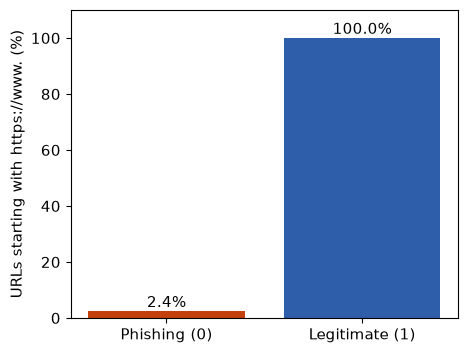

In [12]:
plt.rcParams.update({"font.size": 11})

# Fig. 1 — the shortcut
rate = www.groupby(df["label"]).mean() * 100
plt.figure(figsize=(5, 4))
bars = plt.bar(["Phishing (0)", "Legitimate (1)"], [rate[0], rate[1]], color=["#C2410C", "#2E5EAA"])
for b, v in zip(bars, [rate[0], rate[1]]):
    plt.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.1f}%", ha="center")
plt.ylim(0, 110); plt.ylabel("URLs starting with https://www. (%)")
plt.savefig("fig1_shortcut.png", dpi=300, bbox_inches="tight"); plt.show()

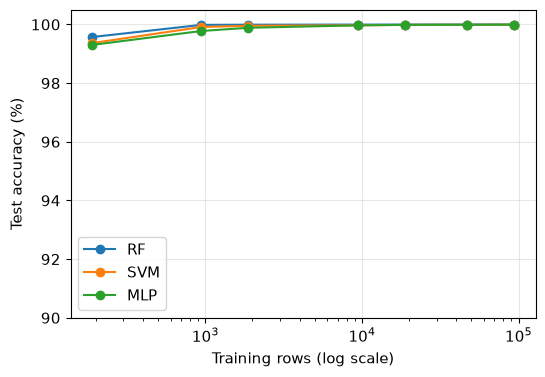

In [13]:
# Fig. 2 — accuracy vs. training rows (mean over seeds)
plt.figure(figsize=(6, 4))
for name in ["RF", "SVM", "MLP"]:
    part = e2[e2["model"] == name].groupby("fraction")[["rows", "accuracy"]].mean()
    plt.plot(part["rows"], part["accuracy"] * 100, marker="o", label=name)
plt.xscale("log"); plt.ylim(90, 100.5)
plt.xlabel("Training rows (log scale)"); plt.ylabel("Test accuracy (%)")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("fig2_learning_curve.png", dpi=300, bbox_inches="tight"); plt.show()

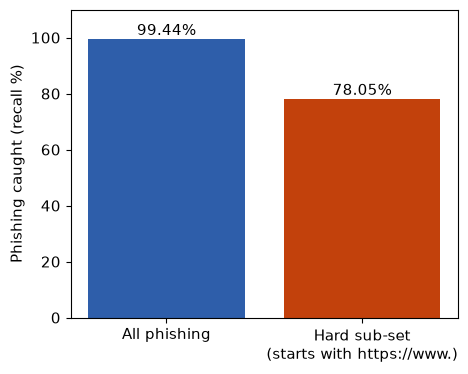

In [14]:
# Fig. 3 — hard test sub-set (mean over seeds)
vals = [e3["recall_all_phishing"].mean() * 100, e3["recall_hard"].mean() * 100]
plt.figure(figsize=(5, 4))
bars = plt.bar(["All phishing", "Hard sub-set\n(starts with https://www.)"], vals, color=["#2E5EAA", "#C2410C"])
for b, v in zip(bars, vals):
    plt.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.2f}%", ha="center")
plt.ylim(0, 110); plt.ylabel("Phishing caught (recall %)")
plt.savefig("fig3_hard_subset.png", dpi=300, bbox_inches="tight"); plt.show()

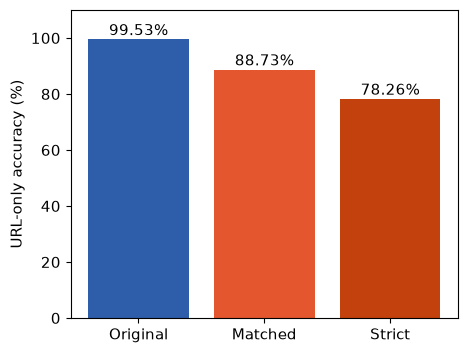

In [15]:
# Fig. 4 — matched sub-sets, URL-only (mean over seeds, 5-fold CV)
url_rows = e5[e5["features"] == "URL-only"].groupby("set", sort=False)["accuracy"].mean() * 100
order = ["original", "matched", "strict"]
vals = [url_rows[s] for s in order]
plt.figure(figsize=(5, 4))
bars = plt.bar(["Original", "Matched", "Strict"], vals, color=["#2E5EAA", "#E4572E", "#C2410C"])
for b, v in zip(bars, vals):
    plt.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.2f}%", ha="center")
plt.ylim(0, 110); plt.ylabel("URL-only accuracy (%)")
plt.savefig("fig4_matched.png", dpi=300, bbox_inches="tight"); plt.show()

In [16]:
# Save all results for the paper
e1.to_csv("results_e1_replication.csv", index=False)
e2.to_csv("results_e2_subsets.csv", index=False)
e3.to_csv("results_e3_hard.csv", index=False)
e5.to_csv("results_e5_matched.csv", index=False)
leak.to_csv("results_leakage_domain_split.csv", index=False)
print("Saved.")

Saved.
